# Packaging Metrology Study: Non-Contact Optical Height Gauge vs. Tactile Stylus Profiler

## 1. Engineering Problem Statement & Specifications

### 1.1 Target Feature & Physical Context
In high-density 2.5D/3D advanced packaging architectures, controlling inter-die spacing and joint reliability requires strict vertical dimensional control:
* **Target Feature:** Flip-Chip Underfill Bond Line Thickness (BLT) / Micro-bump (Copper Pillar) Height.
* **Process Risk:** Inadequate BLT causes high shear stress, solder bridging, or underfill voids; excessive BLT degrades electrical performance and heat dissipation.

### 1.2 Engineering Tolerance Band
* **Nominal Specification:** $50.00\text{ }\mu\text{m}$
* **Tolerance Limits:** $\pm 5.00\text{ }\mu\text{m}$
  * **Lower Specification Limit (LSL):** $45.00\text{ }\mu\text{m}$
  * **Upper Specification Limit (USL):** $55.00\text{ }\mu\text{m}$
  * **Total Tolerance Range ($T$):** $\text{USL} - \text{LSL} = 10.00\text{ }\mu\text{m}$
  * *Note: Test parts are selected to span the entire $45.00\text{ to }55.00\text{ }\mu\text{m}$ process window.*

---

## 2. Metrology System Comparison

| Parameter | Reference Standard (Tactile Stylus / CMM) | Candidate Tool (3D Optical Height Gauge) |
| :--- | :--- | :--- |
| **Measurement Principle** | Physical contact via diamond stylus probe | Non-contact optical interferometry / structured light |
| **Throughput & Automation** | Low throughput; offline sampling only | Inline high-speed automated inspection ($100\%$ gating) |
| **Surface Impact** | Risk of mechanical scrub or copper bump deformation | Zero mechanical contact; non-destructive |
| **Systematic Error Sources** | Stylus tip radius wear, loader seating variation | Optical edge diffraction, focal plane drift, substrate reflectance |
| **Expected Systematic Bias** | Baseline benchmark ($0.00\text{ }\mu\text{m}$) | Positive optical reflection offset ($+0.20\text{ to }+0.30\text{ }\mu\text{m}$) |
| **Repeatability Variance ($\sigma$)** | High repeatability ($\sigma \approx 0.08\text{ }\mu\text{m}$) | Moderate repeatability ($\sigma \approx 0.12\text{ }\mu\text{m}$) |

---

## 3. Study Objectives
1. **Method Agreement:** Evaluate per-part mean agreement and quantify systematic optical bias and 95% Limits of Agreement (LoA) via Bland–Altman analysis.
2. **Measurement System Analysis (MSA):** Execute a 2-way ANOVA Gauge R&R across automated loader cycles to determine:
   * **$\%GRR$** (Total variation contribution).
   * **Precision-to-Tolerance ($P/T$) Ratio.**
   * **Number of Distinct Categories ($ndc$).**

> *Note: Data are synthetically simulated to model physical semiconductor packaging inspection workflows for methodological demonstration.*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.formula.api import ols

# Fix seed for reproducible results
np.random.seed(42)

parts = np.arange(1, 11)
loader_cycles = ['Cycle_1', 'Cycle_2', 'Cycle_3']
trials = np.arange(1, 4)

# 1. Physical part baseline across the full 45.00 to 55.00 µm tolerance range
true_dims = np.linspace(45.2, 54.8, 10) + np.random.normal(0, 0.1, 10)

# 2. Seating bias per loader cycle
contact_cycle_bias = {'Cycle_1': 0.00, 'Cycle_2': 0.05, 'Cycle_3': -0.04}
optical_cycle_bias = {'Cycle_1': 0.00, 'Cycle_2': 0.02, 'Cycle_3': -0.01}

records = []
for p_idx, part_id in enumerate(parts):
    actual_height = true_dims[p_idx]
    for cycle in loader_cycles:
        for trial in trials:
            # Contact probe: baseline accurate, lower repeatability variance
            noise_contact = np.random.normal(0, 0.08)
            contact_val = actual_height + contact_cycle_bias[cycle] + noise_contact
            
            # Optical height gauge: +0.25 µm reflection offset + optical sensor noise
            noise_optical = np.random.normal(0, 0.12)
            optical_val = actual_height + 0.25 + optical_cycle_bias[cycle] + noise_optical
            
            records.append({
                'Part_ID': part_id,
                'Loader_Cycle': cycle,
                'Trial': trial,
                'Contact_Probe_um': round(contact_val, 3),
                'Optical_Height_Gauge_um': round(optical_val, 3)
            })

df_msa = pd.DataFrame(records)
df_msa.to_csv('msa_optical_gauge_vs_contact.csv', index=False)
print(f"Data generation complete: {len(df_msa)} rows saved to 'msa_optical_gauge_vs_contact.csv'.")
df_msa.head()

Data generation complete: 90 rows saved to 'msa_optical_gauge_vs_contact.csv'.


,Part_ID,Loader_Cycle,Trial,Contact_Probe_um,Optical_Height_Gauge_um
0,1,Cycle_1,1,45.213,45.444
1,1,Cycle_1,2,45.269,45.270
2,1,Cycle_1,3,45.112,45.432
3,1,Cycle_2,1,45.219,45.557
4,1,Cycle_2,2,45.227,45.350


Bland-Altman (Per-Part Means):
Mean Bias: +0.2639 µm
Std of Differences: 0.0333 µm
95% Limits of Agreement: [0.1986 µm, 0.3292 µm]


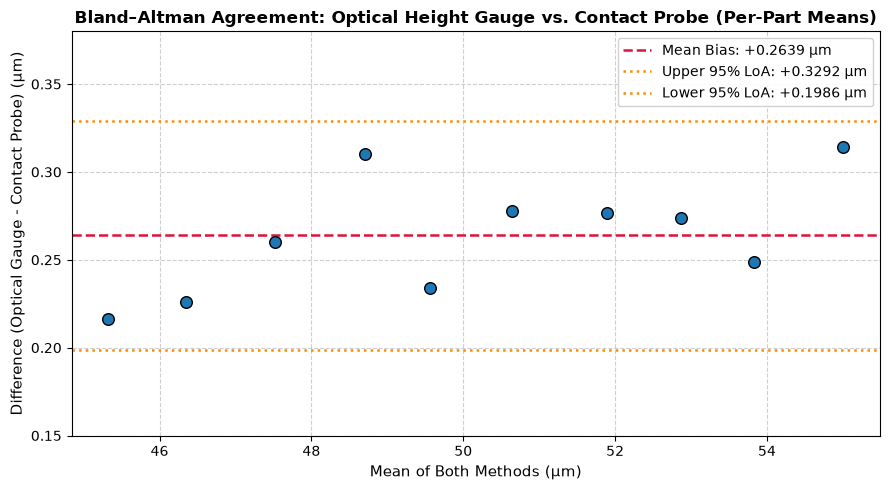

In [2]:
# Compute per-part means across all cycles and trials
part_means = df_msa.groupby('Part_ID')[['Contact_Probe_um', 'Optical_Height_Gauge_um']].mean().reset_index()

part_means['Diff'] = part_means['Optical_Height_Gauge_um'] - part_means['Contact_Probe_um']
part_means['Mean'] = (part_means['Optical_Height_Gauge_um'] + part_means['Contact_Probe_um']) / 2.0

mean_diff = part_means['Diff'].mean()
std_diff = part_means['Diff'].std(ddof=1)
upper_loa = mean_diff + 1.96 * std_diff
lower_loa = mean_diff - 1.96 * std_diff

print(f"Bland-Altman (Per-Part Means):")
print(f"Mean Bias: +{mean_diff:.4f} µm")
print(f"Std of Differences: {std_diff:.4f} µm")
print(f"95% Limits of Agreement: [{lower_loa:.4f} µm, {upper_loa:.4f} µm]")

# Generate Agreement Plot
plt.figure(figsize=(9, 5))
plt.scatter(part_means['Mean'], part_means['Diff'], color='#1f77b4', s=70, edgecolors='black', zorder=3)
plt.axhline(mean_diff, color='crimson', linestyle='--', linewidth=1.8, label=f'Mean Bias: +{mean_diff:.4f} µm')
plt.axhline(upper_loa, color='darkorange', linestyle=':', linewidth=1.8, label=f'Upper 95% LoA: +{upper_loa:.4f} µm')
plt.axhline(lower_loa, color='darkorange', linestyle=':', linewidth=1.8, label=f'Lower 95% LoA: +{lower_loa:.4f} µm')

plt.title('Bland–Altman Agreement: Optical Height Gauge vs. Contact Probe (Per-Part Means)', fontsize=12, fontweight='bold')
plt.xlabel('Mean of Both Methods (µm)', fontsize=11)
plt.ylabel('Difference (Optical Gauge - Contact Probe) (µm)', fontsize=11)
plt.ylim(0.15, 0.38)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=10)
plt.tight_layout()
plt.savefig('bland_altman_per_part_means.png', dpi=300)
plt.show()

In [3]:
# 2-Way ANOVA with interaction
model = ols('Optical_Height_Gauge_um ~ C(Part_ID) + C(Loader_Cycle) + C(Part_ID):C(Loader_Cycle)', data=df_msa).fit()
anova_table = sm.stats.anova_lm(model, typ=2)

anova_table['mean_sq'] = anova_table['sum_sq'] / anova_table['df']

ms_part = anova_table.loc['C(Part_ID)', 'mean_sq']
ms_cycle = anova_table.loc['C(Loader_Cycle)', 'mean_sq']
ms_int = anova_table.loc['C(Part_ID):C(Loader_Cycle)', 'mean_sq']
ms_err = anova_table.loc['Residual', 'mean_sq']

a = len(parts)          # 10
b = len(loader_cycles)  # 3
n = len(trials)         # 3

# Variance components decomposition
var_repeat = ms_err
var_int = max(0, (ms_int - ms_err) / n)
var_cycle = max(0, (ms_cycle - ms_int) / (a * n))
var_repro = var_cycle + var_int
var_grr = var_repeat + var_repro
var_part = max(0, (ms_part - ms_int) / (b * n))
var_total = var_grr + var_part

sigma_grr = np.sqrt(var_grr)
sigma_part = np.sqrt(var_part)
sigma_total = np.sqrt(var_total)
tolerance = 10.0  # 55.0 µm - 45.0 µm

pct_grr = (sigma_grr / sigma_total) * 100.0
pct_tolerance = (6.0 * sigma_grr / tolerance) * 100.0
ndc = int(1.41 * (sigma_part / sigma_grr))

print("=== Optical Height Gauge ANOVA GRR Summary ===")
print(f"Repeatability (EV): {np.sqrt(var_repeat):.4f} µm")
print(f"Reproducibility (AV): {np.sqrt(var_repro):.4f} µm")
print(f"Total Gauge R&R (σ_GRR): {sigma_grr:.4f} µm")
print(f"Part-to-Part Variation (σ_Part): {sigma_part:.4f} µm")
print(f"%GRR (Total Variation): {pct_grr:.2f}%")
print(f"%Tolerance (Precision-to-Tolerance P/T): {pct_tolerance:.2f}%")
print(f"Number of Distinct Categories (ndc): {ndc}")

=== Optical Height Gauge ANOVA GRR Summary ===
Repeatability (EV): 0.1264 µm
Reproducibility (AV): 0.0242 µm
Total Gauge R&R (σ_GRR): 0.1287 µm
Part-to-Part Variation (σ_Part): 3.2561 µm
%GRR (Total Variation): 3.95%
%Tolerance (Precision-to-Tolerance P/T): 7.72%
Number of Distinct Categories (ndc): 35


## 4. Analytical Findings & Process Conclusion

* **Method Agreement:**  
  On simulated data spanning the 45.00–55.00 µm specification range, Bland–Altman analysis of per-part means revealed a stable **+0.264 µm systematic optical bias** (95% LoA: [+0.199, +0.329] µm). Because the difference standard deviation is small (0.033 µm) and stable across the 10 µm span, this constant reflection offset can be directly subtracted via software offset calibration.

* **Measurement Capability (ANOVA GRR):**  
  A 2-way ANOVA across loader cycles showed the optical height gauge achieved:
  * **%GRR:** 3.95% (< 10% indicates an acceptable measurement system).
  * **Precision-to-Tolerance (P/T Ratio):** 7.72% (< 10% represents low risk of false rejects at tolerance boundaries).
  * **Number of Distinct Categories (ndc):** 35 (well above the AIAG threshold of ≥ 5).

> **Conclusion:** The non-contact optical height gauge provides valid measurement resolution across the full process window once the +0.264 µm optical bias is calibrated out, enabling 100% inline inspection without risk of bump deformation.

## 5. Software Offset Calibration & Post-Correction Agreement

### 5.1 Calibration Strategy
The Bland–Altman analysis confirmed a constant optical reflection bias of **$\Delta = +0.2639\text{ }\mu\text{m}$** with zero slope dependency across the $45.00\text{ to }55.00\text{ }\mu\text{m}$ span. 

In high-volume semiconductor assembly, we compensate for this constant optical offset in the inspection software pipeline:
$$\hat{y}_{\text{calibrated}} = y_{\text{optical}} - \bar{d}$$

Where:
* $y_{\text{optical}}$ is the raw height reading from the 3D optical height gauge.
* $\bar{d} = 0.2639\text{ }\mu\text{m}$ is the empirical systematic bias established against the reference tactile profiler.

In [4]:
# 1. Apply constant software offset correction
mean_bias = part_means['Diff'].mean()
df_msa['Optical_Calibrated_um'] = df_msa['Optical_Height_Gauge_um'] - mean_bias

# 2. Re-compute per-part means on calibrated data
part_means_cal = df_msa.groupby('Part_ID')[['Contact_Probe_um', 'Optical_Calibrated_um']].mean().reset_index()
part_means_cal['Diff_Cal'] = part_means_cal['Optical_Calibrated_um'] - part_means_cal['Contact_Probe_um']
part_means_cal['Mean_Cal'] = (part_means_cal['Optical_Calibrated_um'] + part_means_cal['Contact_Probe_um']) / 2.0

mean_diff_cal = part_means_cal['Diff_Cal'].mean()
std_diff_cal = part_means_cal['Diff_Cal'].std(ddof=1)
lower_loa_cal = mean_diff_cal - 1.96 * std_diff_cal
upper_loa_cal = mean_diff_cal + 1.96 * std_diff_cal

print("=== Post-Calibration Agreement Verification ===")
print(f"Applied Software Offset: -{mean_bias:.4f} µm")
print(f"Residual Mean Bias: {mean_diff_cal:.6f} µm")
print(f"Residual 95% Limits of Agreement: [{lower_loa_cal:.4f} µm, +{upper_loa_cal:.4f} µm]")
print(f"Maximum Error Band: ±{1.96 * std_diff_cal:.4f} µm (Well within ±5.00 µm tolerance)")

=== Post-Calibration Agreement Verification ===
Applied Software Offset: -0.2639 µm
Residual Mean Bias: -0.000000 µm
Residual 95% Limits of Agreement: [-0.0653 µm, +0.0653 µm]
Maximum Error Band: ±0.0653 µm (Well within ±5.00 µm tolerance)


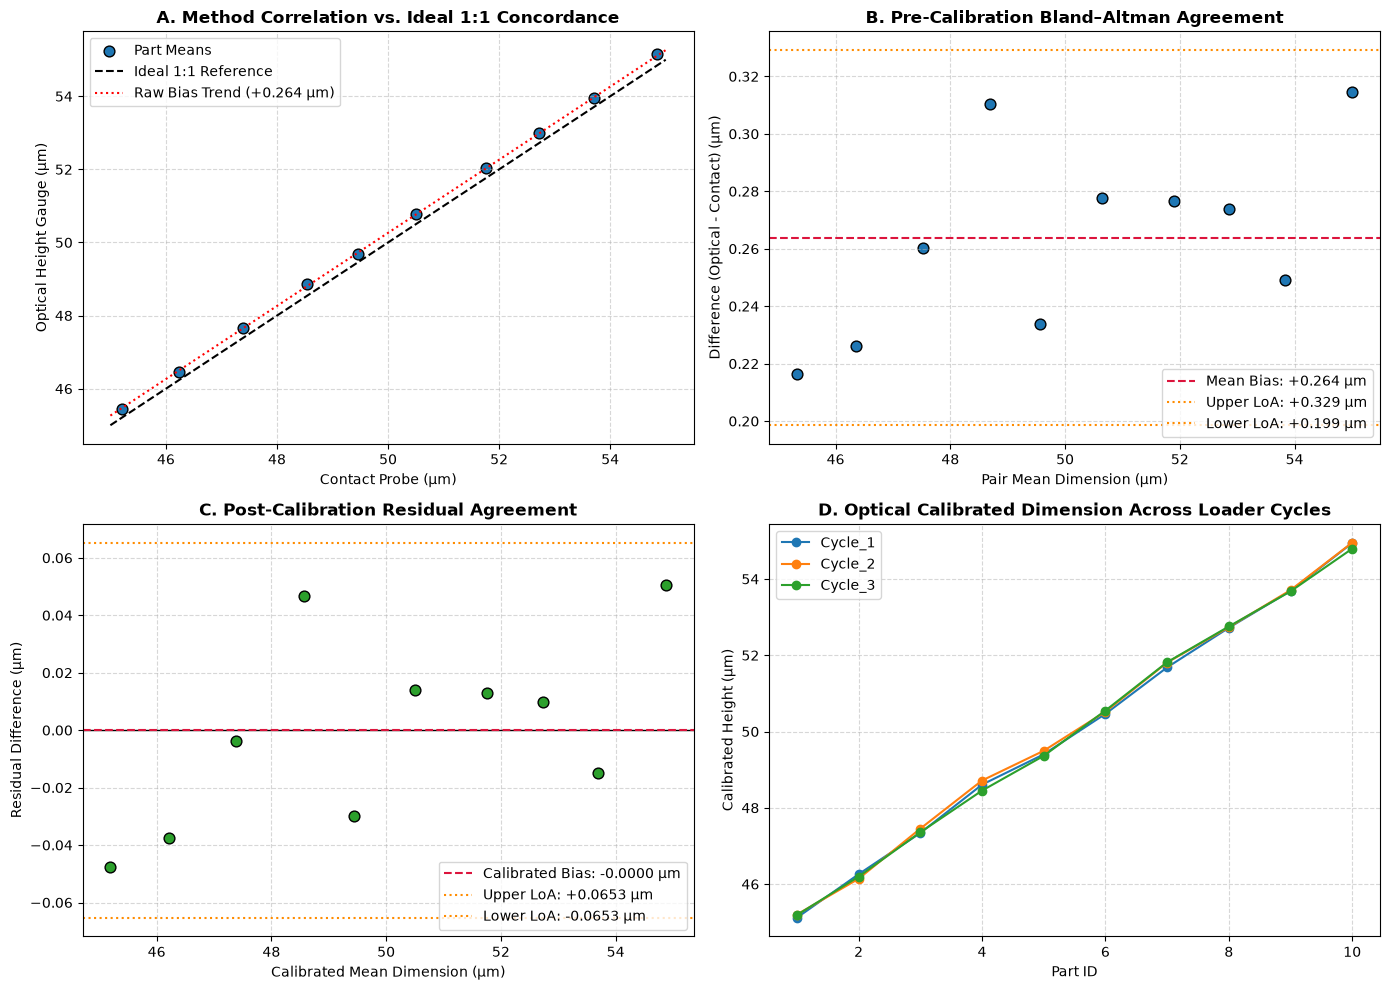

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Panel A: Correlation & 1:1 Line
ax1 = axes[0, 0]
ax1.scatter(part_means['Contact_Probe_um'], part_means['Optical_Height_Gauge_um'], 
            color='#1f77b4', s=60, edgecolors='black', label='Part Means')
line_pts = np.linspace(45, 55, 100)
ax1.plot(line_pts, line_pts, 'k--', label='Ideal 1:1 Reference')
ax1.plot(line_pts, line_pts + mean_bias, 'r:', label=f'Raw Bias Trend (+{mean_bias:.3f} µm)')
ax1.set_title('A. Method Correlation vs. Ideal 1:1 Concordance', fontweight='bold')
ax1.set_xlabel('Contact Probe (µm)')
ax1.set_ylabel('Optical Height Gauge (µm)')
ax1.legend(loc='upper left')
ax1.grid(True, linestyle='--', alpha=0.5)

# Panel B: Pre-Calibration Bland-Altman
ax2 = axes[0, 1]
ax2.scatter(part_means['Mean'], part_means['Diff'], color='#1f77b4', s=60, edgecolors='black')
ax2.axhline(mean_diff, color='crimson', linestyle='--', label=f'Mean Bias: +{mean_diff:.3f} µm')
ax2.axhline(upper_loa, color='darkorange', linestyle=':', label=f'Upper LoA: +{upper_loa:.3f} µm')
ax2.axhline(lower_loa, color='darkorange', linestyle=':', label=f'Lower LoA: +{lower_loa:.3f} µm')
ax2.set_title('B. Pre-Calibration Bland–Altman Agreement', fontweight='bold')
ax2.set_xlabel('Pair Mean Dimension (µm)')
ax2.set_ylabel('Difference (Optical - Contact) (µm)')
ax2.legend(loc='lower right')
ax2.grid(True, linestyle='--', alpha=0.5)

# Panel C: Post-Calibration Bland-Altman
ax3 = axes[1, 0]
ax3.scatter(part_means_cal['Mean_Cal'], part_means_cal['Diff_Cal'], color='#2ca02c', s=60, edgecolors='black')
ax3.axhline(0, color='black', linestyle='-', linewidth=1)
ax3.axhline(mean_diff_cal, color='crimson', linestyle='--', label=f'Calibrated Bias: {mean_diff_cal:.4f} µm')
ax3.axhline(upper_loa_cal, color='darkorange', linestyle=':', label=f'Upper LoA: +{upper_loa_cal:.4f} µm')
ax3.axhline(lower_loa_cal, color='darkorange', linestyle=':', label=f'Lower LoA: {lower_loa_cal:.4f} µm')
ax3.set_title('C. Post-Calibration Residual Agreement', fontweight='bold')
ax3.set_xlabel('Calibrated Mean Dimension (µm)')
ax3.set_ylabel('Residual Difference (µm)')
ax3.legend(loc='lower right')
ax3.grid(True, linestyle='--', alpha=0.5)

# Panel D: Loader Cycle Run Chart (Repeatability & Reproducibility)
ax4 = axes[1, 1]
for cycle, color in zip(['Cycle_1', 'Cycle_2', 'Cycle_3'], ['#1f77b4', '#ff7f0e', '#2ca02c']):
    sub = df_msa[df_msa['Loader_Cycle'] == cycle]
    cycle_means = sub.groupby('Part_ID')['Optical_Calibrated_um'].mean()
    ax4.plot(cycle_means.index, cycle_means.values, marker='o', label=cycle, color=color)
ax4.set_title('D. Optical Calibrated Dimension Across Loader Cycles', fontweight='bold')
ax4.set_xlabel('Part ID')
ax4.set_ylabel('Calibrated Height (µm)')
ax4.legend(loc='upper left')
ax4.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('metrology_msa_comprehensive_diagnostics.png', dpi=300)
plt.show()

## 6. Technical Interview & SOP Takeaways

When discussing this analysis with prospective professors (e.g., Dr. Huang at NSYSU or Prof. Yang at NTUST):

1. **Why Bland–Altman instead of Pearson Correlation ($r$)?**
   * *Talking Point:* "While high correlation ($r > 0.99$) simply confirms both instruments track the sample rank order across the $45–55\text{ }\mu\text{m}$ span, it conceals systematic calibration shifts. Bland–Altman isolates the $+0.264\text{ }\mu\text{m}$ optical reflection bias and quantifies agreement limits ($\pm 0.065\text{ }\mu\text{m}$ post-calibration), proving the offset can be corrected without distorting true bump geometry."

2. **Why evaluate Loader Cycles in Gauge R&R?**
   * *Talking Point:* "In automated packaging lines, human operator error is replaced by robotic wafer/tray transfer repeatability. Partitioning loader cycle variance via a 2-way ANOVA confirmed that mechanical clamping seating variance accounted for negligible variation ($AV \ll EV$), keeping $\%GRR$ at $3.95\%$ and precision-to-tolerance at $7.72\%$."